# Janelas ACE completas: 3, 7 e 14 dias de entrada + 72 horas de alvo

Este notebook carrega as três pastas em `data/training_windows/`, confere os arquivos e produz figuras de cobertura, distribuição e exemplos de entrada/alvo. As entradas têm nove variáveis ACE/SWEPAM + ACE/MAG; o alvo é a velocidade SWEPAM horária nas 72 horas seguintes.

A seleção foi **estrita**: nenhuma célula exportada é ausente ou interpolada. Medições recuperadas do mesmo arquivo operacional são aceitas como observações, embora nenhuma janela selecionada as contenha. As origens `t0` ocorrem a cada seis horas. A entrada termina em `t0−1 h` (hipótese local de uma hora de latência) e o alvo cobre `t0+1 h` a `t0+72 h`. O conjunto não contém partições de treino/validação/teste.


In [17]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data/training_windows/summary.json").exists():
            return candidate
    raise FileNotFoundError("Execute o notebook a partir da pasta do projeto ou de notebooks/.")


ROOT = find_project_root()
DATA_DIR = ROOT / "data/training_windows"
FIG_DIR = DATA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DURATIONS = (3, 7, 14)
COLORS = {3: "#168a62", 7: "#2878b5", 14: "#6a51a3"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
print("Projeto:", ROOT)
print("Figuras:", FIG_DIR)


Projeto: /scratch/cptec/adriano.almeida2/laboratory/benchlab
Figuras: /scratch/cptec/adriano.almeida2/laboratory/benchlab/data/training_windows/figures


## Carregamento e verificação

`inputs.npy` tem formato `(amostras, horas de entrada, 9)`; `targets.npy` tem `(amostras, 72)`. Usamos *memory mapping* para evitar carregar todos os arrays na memória de uma vez. A linha `i` em `samples.parquet` identifica a origem temporal da linha `i` em ambos os arrays.


In [18]:
datasets = {}
source_path = ROOT / "data/quality/ace_interpolated_all_internal.parquet"
source_sha256 = hashlib.sha256(source_path.read_bytes()).hexdigest()

for days in DURATIONS:
    folder = DATA_DIR / f"{days}d_72h"
    manifest = json.loads((folder / "manifest.json").read_text(encoding="utf-8"))
    X = np.load(folder / "inputs.npy", mmap_mode="r", allow_pickle=False)
    y = np.load(folder / "targets.npy", mmap_mode="r", allow_pickle=False)
    samples = pd.read_parquet(folder / "samples.parquet")
    n = manifest["samples"]
    assert X.shape == (n, 24 * days, 9)
    assert y.shape == (n, 72)
    assert len(samples) == n and samples.sample_id.tolist() == list(range(n))
    assert X.dtype == np.float32 and y.dtype == np.float32
    assert np.isfinite(X).all() and np.isfinite(y).all()
    assert manifest["source_sha256"] == source_sha256
    assert samples.t0_utc.is_monotonic_increasing and not samples.t0_utc.duplicated().any()
    assert (samples.input_start_utc == samples.t0_utc - pd.Timedelta(hours=24 * days)).all()
    assert (samples.input_end_utc == samples.t0_utc - pd.Timedelta(hours=1)).all()
    assert (samples.target_start_utc == samples.t0_utc + pd.Timedelta(hours=1)).all()
    assert (samples.target_end_utc == samples.t0_utc + pd.Timedelta(hours=72)).all()
    datasets[days] = {"X": X, "y": y, "samples": samples, "manifest": manifest}

feature_names = datasets[7]["manifest"]["input_features"]
feature_units = datasets[7]["manifest"]["input_units"]
print("Colunas de entrada, nesta ordem:")
for position, (name, unit) in enumerate(zip(feature_names, feature_units)):
    print(f"  {position}: {name} ({unit})")
print("Verificação concluída: formatos, valores finitos, hash e horários corretos.")


Colunas de entrada, nesta ordem:
  0: speed_km_s (km/s)
  1: density_cm3 (cm^-3)
  2: temperature_k (K)
  3: bx_gsm_nt (nT)
  4: by_gsm_nt (nT)
  5: bz_gsm_nt (nT)
  6: bt_nt (nT)
  7: latitude_gsm_deg (degrees)
  8: longitude_gsm_deg (degrees)
Verificação concluída: formatos, valores finitos, hash e horários corretos.


In [19]:
rows = []
for days, item in datasets.items():
    samples, y = item["samples"], item["y"]
    target_start_hours = samples.target_start_utc.to_numpy(dtype="datetime64[h]").astype(np.int64)
    unique_target_hours = np.unique(target_start_hours[:, None] + np.arange(72)).size
    rows.append({
        "entrada_dias": days,
        "amostras": len(samples),
        "primeiro_t0_utc": samples.t0_utc.iloc[0],
        "ultimo_t0_utc": samples.t0_utc.iloc[-1],
        "horas_alvo_distintas": unique_target_hours,
        "repeticoes_medias_alvo": round(len(samples) * 72 / unique_target_hours, 2),
        "velocidade_alvo_min_km_s": round(float(np.min(y)), 1),
        "velocidade_alvo_max_km_s": round(float(np.max(y)), 1),
    })
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
assert set(datasets[14]["samples"].t0_utc).issubset(set(datasets[7]["samples"].t0_utc))
assert set(datasets[7]["samples"].t0_utc).issubset(set(datasets[3]["samples"].t0_utc))


 entrada_dias  amostras           primeiro_t0_utc             ultimo_t0_utc  horas_alvo_distintas  repeticoes_medias_alvo  velocidade_alvo_min_km_s  velocidade_alvo_max_km_s
            3      6148 2000-08-04 00:00:00+00:00 2011-10-21 12:00:00+00:00                 60186                    7.35                     225.8                    1196.4
            7      2207 2000-08-08 00:00:00+00:00 2011-10-07 12:00:00+00:00                 22944                    6.93                     245.6                     931.2
           14       204 2003-01-07 00:00:00+00:00 2010-07-30 18:00:00+00:00                  2082                    7.05                     246.8                     752.1


## Cobertura temporal

O gráfico conta as origens elegíveis por ano. Uma janela de 14 dias precisa de mais observações consecutivas, portanto sobra menos exemplos. **A ausência de barras após 2011 é resultado do filtro estrito**, não ausência total de observações ACE.


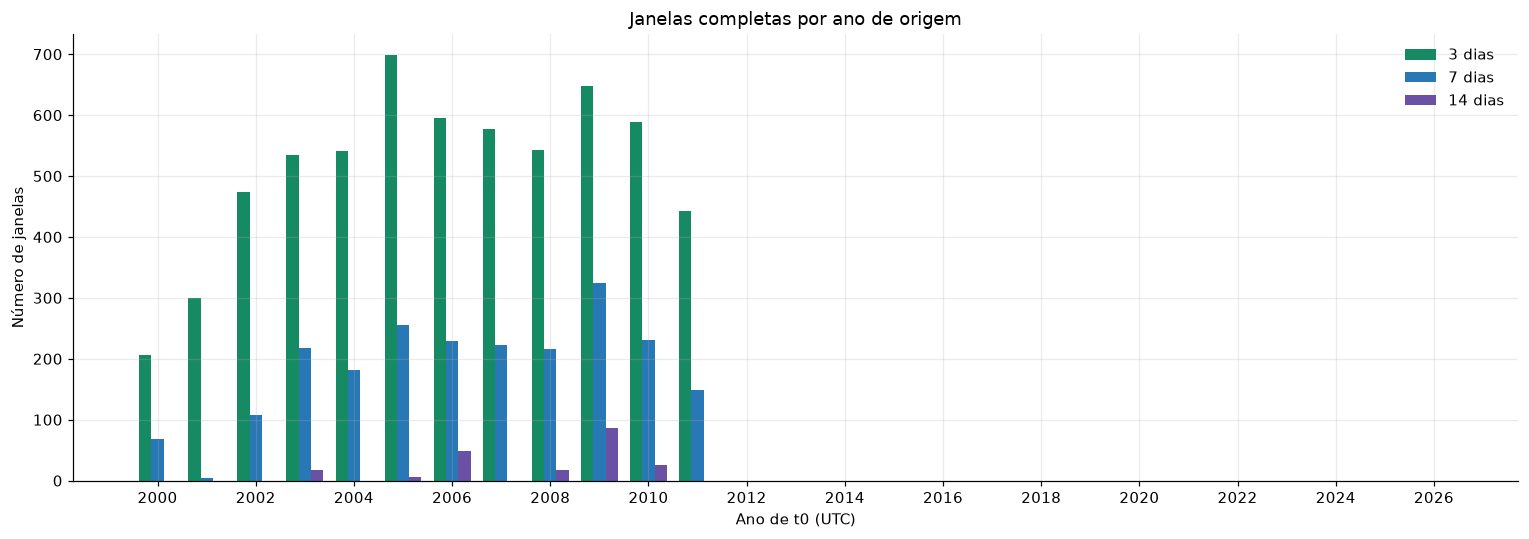

In [20]:
years = np.arange(2000, 2027)
fig, ax = plt.subplots(figsize=(14, 5))
width = 0.25
for offset, days in enumerate(DURATIONS):
    counts = datasets[days]["samples"].t0_utc.dt.year.value_counts().reindex(years, fill_value=0)
    ax.bar(years + (offset - 1) * width, counts.to_numpy(), width=width,
           color=COLORS[days], label=f"{days} dias")
ax.set(title="Janelas completas por ano de origem", xlabel="Ano de t0 (UTC)", ylabel="Número de janelas")
ax.set_xticks(np.arange(2000, 2027, 2))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "janelas_completas_por_ano.png", bbox_inches="tight")
plt.show()


## Exemplo da mesma origem nos três conjuntos

Escolhemos uma origem presente nas três pastas. As entradas mais curtas são o trecho final da entrada de 14 dias; a linha vermelha é o alvo observado. O instante `t0` não entra nem na entrada nem no alvo.


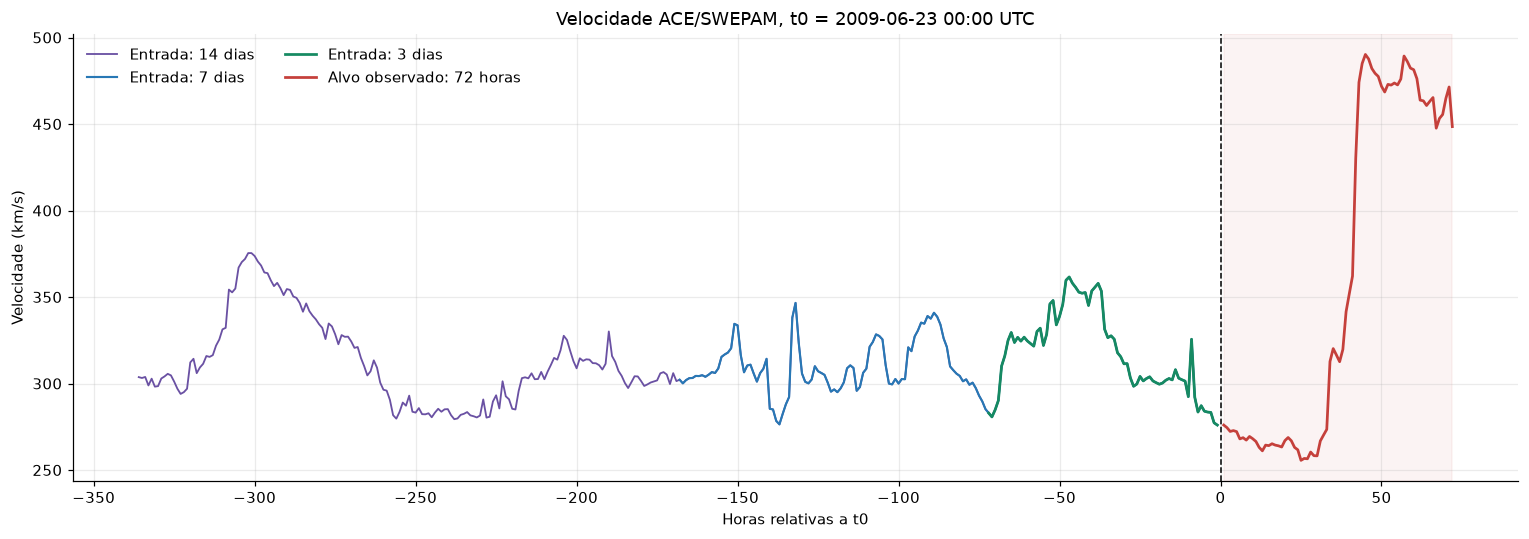

In [21]:
reference = datasets[14]["samples"]
example_t0 = reference.t0_utc.iloc[len(reference) // 2]
fig, ax = plt.subplots(figsize=(14, 5))
for days in (14, 7, 3):
    item = datasets[days]
    index = int(item["samples"].t0_utc.searchsorted(example_t0))
    assert item["samples"].t0_utc.iloc[index] == example_t0
    speed = item["X"][index, :, 0]
    ax.plot(np.arange(-24 * days, 0), speed, color=COLORS[days],
            linewidth={14: 1.2, 7: 1.4, 3: 1.8}[days], label=f"Entrada: {days} dias")
    if days == 7:
        example_index_7d = index
    if days == 14:
        target = item["y"][index]
ax.plot(np.arange(1, 73), target, color="#c5403b", linewidth=1.8,
        label="Alvo observado: 72 horas")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvspan(1, 72, color="#c5403b", alpha=0.06)
ax.set(title=f"Velocidade ACE/SWEPAM, t0 = {example_t0:%Y-%m-%d %H:%M} UTC",
       xlabel="Horas relativas a t0", ylabel="Velocidade (km/s)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "exemplo_entrada_e_alvo.png", bbox_inches="tight")
plt.show()


## Nove variáveis de entrada

Aqui está a entrada de sete dias do mesmo exemplo. Bx, By, Bz e |B| estão em nT; latitude e longitude estão em graus. A longitude é circular: saltos visuais entre 0° e 360° não indicam, por si, salto físico equivalente.


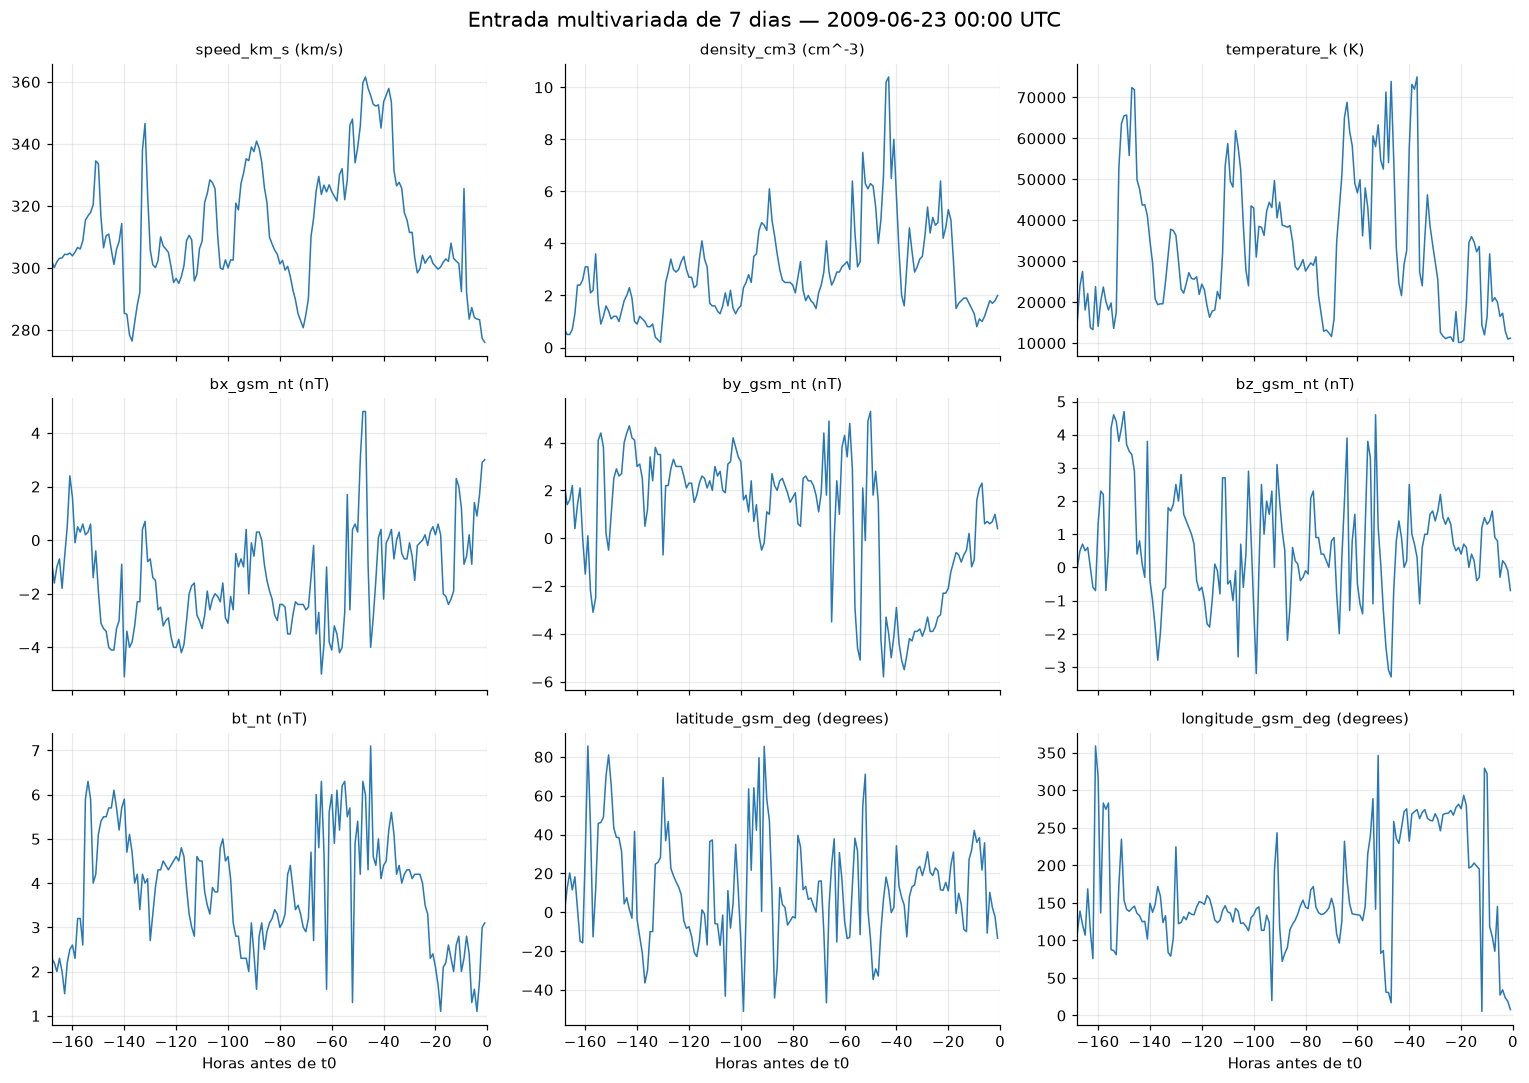

In [22]:
X_example = datasets[7]["X"][example_index_7d]
relative_hours = np.arange(-X_example.shape[0], 0)
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True)
for column, ax in enumerate(axes.flat):
    ax.plot(relative_hours, X_example[:, column], color="#2878b5", linewidth=1)
    ax.set_title(f"{feature_names[column]} ({feature_units[column]})", fontsize=10)
    ax.set_xlim(relative_hours[0], 0)
    ax.grid(alpha=0.25)
for ax in axes[-1]:
    ax.set_xlabel("Horas antes de t0")
fig.suptitle(f"Entrada multivariada de 7 dias — {example_t0:%Y-%m-%d %H:%M} UTC", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "exemplo_9_variaveis_7d.png", bbox_inches="tight")
plt.show()


## Distribuição e perfil dos alvos

A primeira figura compara a **velocidade média das 72 horas futuras por exemplo**. A segunda mostra a mediana e a faixa entre os percentis 10 e 90 em cada horizonte. Essas curvas descrevem subconjuntos com períodos diferentes; elas não medem a qualidade de nenhum modelo nem constituem uma comparação controlada entre durações. Janelas vizinhas compartilham muitas horas, como indica a tabela acima.


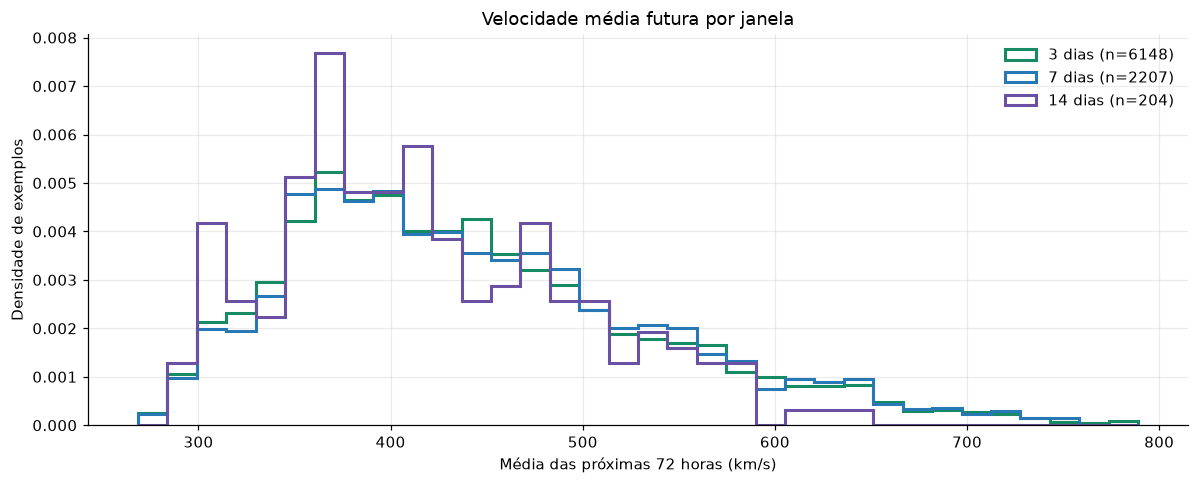

In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
all_means = np.concatenate([np.asarray(datasets[d]["y"]).mean(axis=1) for d in DURATIONS])
bins = np.linspace(float(all_means.min()), float(all_means.max()), 35)
for days in DURATIONS:
    means = np.asarray(datasets[days]["y"]).mean(axis=1)
    ax.hist(means, bins=bins, density=True, histtype="step", linewidth=2,
            color=COLORS[days], label=f"{days} dias (n={len(means)})")
ax.set(title="Velocidade média futura por janela", xlabel="Média das próximas 72 horas (km/s)",
       ylabel="Densidade de exemplos")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "distribuicao_velocidade_alvo.png", bbox_inches="tight")
plt.show()


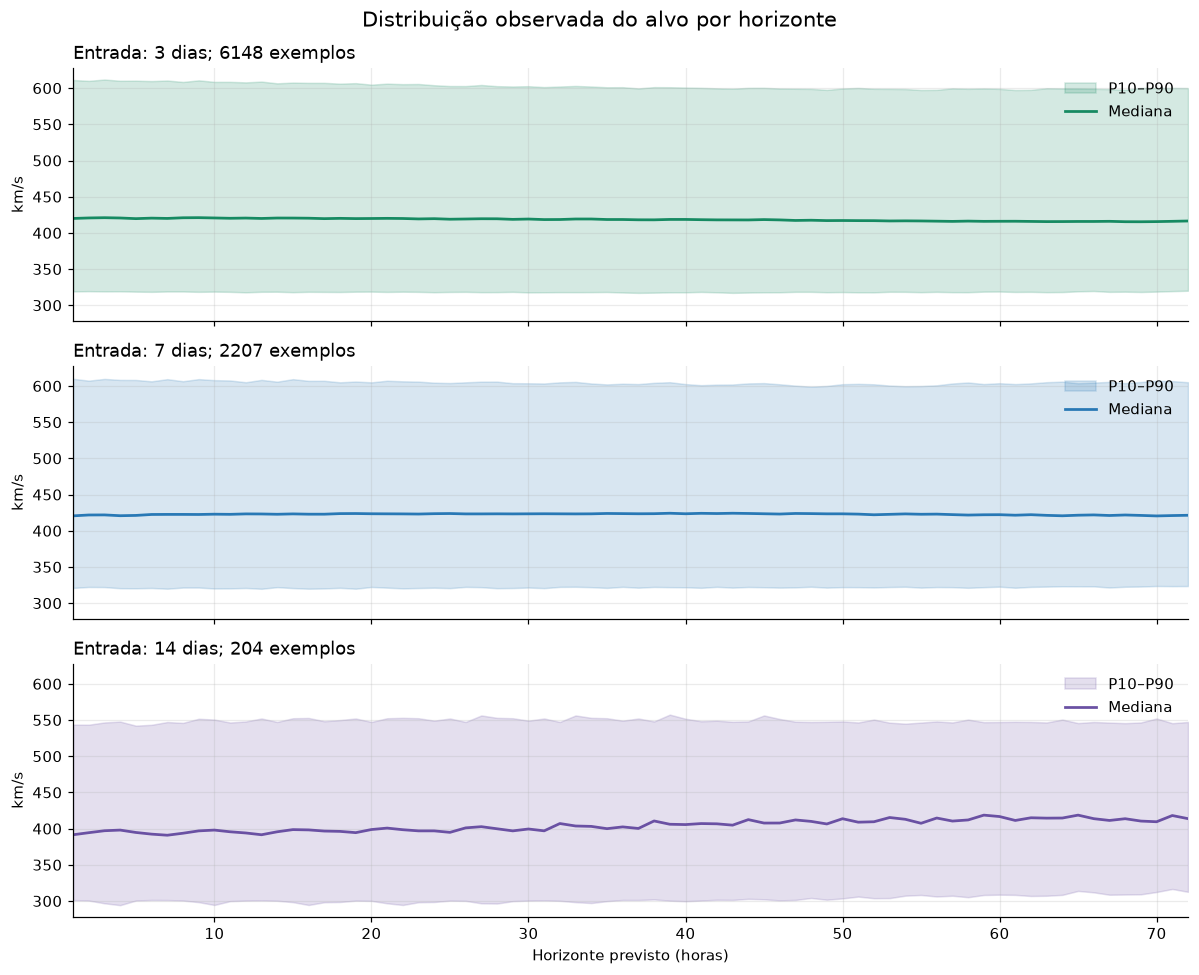

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
horizons = np.arange(1, 73)
for ax, days in zip(axes, DURATIONS):
    y = np.asarray(datasets[days]["y"])
    p10, median, p90 = np.quantile(y, [0.10, 0.50, 0.90], axis=0)
    ax.fill_between(horizons, p10, p90, color=COLORS[days], alpha=0.18, label="P10–P90")
    ax.plot(horizons, median, color=COLORS[days], linewidth=1.8, label="Mediana")
    ax.set_title(f"Entrada: {days} dias; {len(y)} exemplos", loc="left")
    ax.set_ylabel("km/s")
    ax.legend(frameon=False, loc="upper right")
axes[-1].set_xlabel("Horizonte previsto (horas)")
axes[-1].set_xlim(1, 72)
fig.suptitle("Distribuição observada do alvo por horizonte", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "perfil_alvo_por_horizonte.png", bbox_inches="tight")
plt.show()


## Uso posterior no treino

`X` e `y` já têm eixos adequados para modelos sequenciais: `(amostras, tempo, variáveis)` e `(amostras, horizonte)`. Os índices são alinhados com `samples.parquet`. **Não faça divisão aleatória por linha**: as janelas se sobrepõem e podem compartilhar alvos. Separe cronologicamente, com intervalo de purga compatível com o horizonte de 72 horas, e avalie cobertura separadamente.

A condição de completude deixa apenas 204 exemplos para a janela de 14 dias e não produz exemplos após 2011, mesmo após incluir medições operacionais recuperadas. Para modelos que representem melhor o período recente, será necessário trabalhar com máscaras de ausência e uma função de perda que ignore alvos não observados; interpolação bilateral usa o futuro e não representa uma entrada operacional em `t0`.
